In [54]:
import torch
from torch import nn

In [55]:
torch.manual_seed(0)

def make_data(n, noise=0.3):
    x = torch.rand(n, 1) * 2 - 1              
    y = 3 * x**2 + 2 + noise * torch.randn(n, 1)
    return x, y

the model learned from x_train and y_train to predict the outpute of new data

In [56]:
x_train, y_train = make_data(15)              
x_test,  y_test  = make_data(200)

this class define the model

In [57]:
class Net(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()                    # always needed
        self.layers = nn.Sequential(
            nn.Linear(1, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden, 1),
        )
    def forward(self, x):
        return self.layers(x)

In [58]:
model = Net()
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

In [59]:
for i in range(3000):
    loss = loss_fn(model(x_train),y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if i%300 == 0:
        with torch.no_grad():
            test_loss = loss_fn(model(x_test),y_test)
            print(i, round(loss.item(), 4), round(test_loss.item(),4) ) 

0 9.867 4.6582
300 0.0231 0.2322
600 0.0146 0.2628
900 0.0126 0.2777
1200 0.0116 0.2945
1500 0.0092 0.3111
1800 0.0067 0.3284
2100 0.005 0.301
2400 0.0031 0.3074
2700 0.0006 0.3439


solve the train

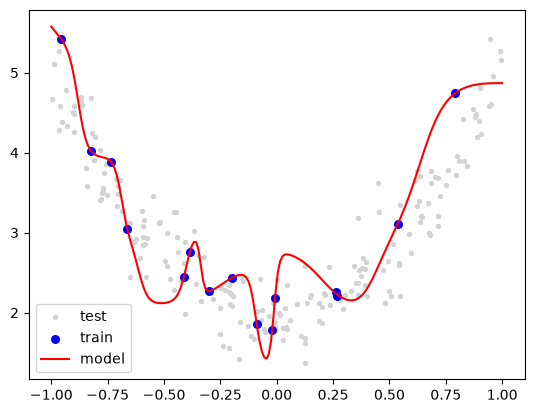

In [60]:
import matplotlib.pyplot as plt
xs = torch.linspace(-1, 1, 200).unsqueeze(1)
with torch.no_grad():
    ys = model(xs)
plt.scatter(x_test, y_test, s=8, color="lightgray", label="test")
plt.scatter(x_train, y_train, s=30, color="blue", label="train")
plt.plot(xs, ys, color="red", label="model")
plt.legend()
plt.show()

In [61]:
model2 = Net()
loss_fn2 = nn.MSELoss()
optimizer2 = torch.optim.Adam(model2.parameters(), lr=0.01)

In [ ]:
x_train2, y_train2 = make_data(200)    #for  a few number test data model memorized the noise and dosen't 
                                       #-actualy learn but for huge test data model cannot memorized and forced to learn the model   
x_test2,  y_test2  = make_data(200)

In [63]:
for i in range(3000):
    loss2 = loss_fn2(model2(x_train2),y_train2)
    optimizer2.zero_grad()
    loss2.backward()
    optimizer2.step()
    if i%300 == 0:
        with torch.no_grad():
            test_loss2 = loss_fn2(model2(x_test2),y_test2)
            print(i, round(loss2.item(), 4), round(test_loss2.item(), 4)) 

0 10.9962 4.9963
300 0.094 0.089
600 0.0927 0.0881
900 0.0924 0.0879
1200 0.092 0.0875
1500 0.0911 0.0874
1800 0.0889 0.0888
2100 0.0864 0.0911
2400 0.0842 0.0934
2700 0.0831 0.0945


In [64]:
class Net2(nn.Module):
    def __init__(self, hidden=4):
        super().__init__()                    # always needed
        self.layers = nn.Sequential(
            nn.Linear(1, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden, 1),
        )
    def forward(self, x):
        return self.layers(x)

In [65]:
model2 = Net2()
loss_fn2 = nn.MSELoss()
optimizer2 = torch.optim.Adam(model.parameters(), lr=0.01)

In [66]:
for i in range(600):
    loss3 = loss_fn2(model(x_train),y_train)
    optimizer.zero_grad()
    loss3.backward()
    optimizer.step()
    if i%300 == 0:
        with torch.no_grad():
            test_loss = loss_fn2(model(x_test),y_test)
            print(i, round(loss.item(), 4), round(test_loss.item(), 4)) 

0 0.0001 0.3423
300 0.0001 0.3444
